# Proyecto final – Segunda entrega
## Factores asociados a la enfermedad cardíaca (Cleveland, UCI)
**Pregunta:** ¿Qué factores clínicos se asocian con la presencia de enfermedad cardíaca en los pacientes evaluados en Cleveland?

El archivo `processed.cleveland.data` debe estar en la misma carpeta que este notebook.

## 1. Carga de datos
El archivo no trae encabezado, así que los nombres se toman de `heart-disease.names`. Los faltantes vienen como `?`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

columnas = ["age","sex","cp","trestbps","chol","fbs","restecg",
            "thalach","exang","oldpeak","slope","ca","thal","num"]
df = pd.read_csv("processed.cleveland.data", header=None, names=columnas, na_values="?")

## 2. Revisión inicial

In [2]:
print("Shape:", df.shape)
print(df.dtypes)
print(df.head().to_string())
print(df.tail().to_string())

Shape: (303, 14)
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
num           int64
dtype: object
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  slope   ca  thal  num
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3    3.0  0.0   6.0    0
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5    2.0  3.0   3.0    2
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6    2.0  2.0   7.0    1
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5    3.0  0.0   3.0    0
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4    1.0  0.0   3.0    0
      age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  slope   ca  thal  num
298  45.

In [3]:
print("Nulos por columna:")
print(df.isnull().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

Nulos por columna:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

Filas duplicadas: 0


Revisión de consistencia: valores únicos de las categóricas y rangos de las numéricas.

In [4]:
for c in ["sex","cp","fbs","restecg","exang","slope","ca","thal","num"]:
    print(c, sorted(df[c].dropna().unique().tolist()))
print(df[["age","trestbps","chol","thalach","oldpeak"]].agg(["min","max"]).T)

sex [0.0, 1.0]
cp [1.0, 2.0, 3.0, 4.0]
fbs [0.0, 1.0]
restecg [0.0, 1.0, 2.0]
exang [0.0, 1.0]
slope [1.0, 2.0, 3.0]
ca [0.0, 1.0, 2.0, 3.0]
thal [3.0, 6.0, 7.0]
num [0, 1, 2, 3, 4]
            min    max
age        29.0   77.0
trestbps   94.0  200.0
chol      126.0  564.0
thalach    71.0  202.0
oldpeak     0.0    6.2


## 3. Limpieza
- **Nulos:** solo 6 celdas (`ca`: 4, `thal`: 2). Se imputan con la **moda** porque son variables discretas o categóricas (un promedio daría códigos que no existen). Eliminar filas haría perder pacientes de una muestra pequeña.
- **Duplicados:** se verifica y se aplica `drop_duplicates()`.
- **Tipos:** los códigos llegan como decimales y se convierten a enteros.

In [5]:
df_limpio = df.copy()
for c in ["ca", "thal"]:
    moda = df_limpio[c].mode()[0]
    print(f"{c}: {df_limpio[c].isnull().sum()} nulos imputados con la moda = {moda}")
    df_limpio[c] = df_limpio[c].fillna(moda)

df_limpio = df_limpio.drop_duplicates()
enteras = [c for c in columnas if c != "oldpeak"]
df_limpio[enteras] = df_limpio[enteras].astype(int)
print("Nulos restantes:", df_limpio.isnull().sum().sum(), "| Shape:", df_limpio.shape)

ca: 4 nulos imputados con la moda = 0.0
thal: 2 nulos imputados con la moda = 3.0
Nulos restantes: 0 | Shape: (303, 14)


### Valores atípicos (regla de 1.5 × IQR)
Se identifican, pero **se conservan**: son valores clínicamente posibles y pueden corresponder justamente a pacientes enfermos.

In [6]:
numericas = ["age","trestbps","chol","thalach","oldpeak"]
for c in numericas:
    q1, q3 = df_limpio[c].quantile([0.25, 0.75])
    li, ls = q1 - 1.5*(q3-q1), q3 + 1.5*(q3-q1)
    fuera = df_limpio[(df_limpio[c] < li) | (df_limpio[c] > ls)][c]
    print(f"{c:9s} atípicos: {len(fuera):2d}  límites: [{li:.1f}, {ls:.1f}]  máx: {df_limpio[c].max()}")

age       atípicos:  0  límites: [28.5, 80.5]  máx: 77
trestbps  atípicos:  9  límites: [90.0, 170.0]  máx: 200
chol      atípicos:  5  límites: [115.0, 371.0]  máx: 564
thalach   atípicos:  1  límites: [84.8, 214.8]  máx: 202
oldpeak   atípicos:  5  límites: [-2.4, 4.0]  máx: 6.2


## 4. Transformación
- Se crea `enfermedad` (0 = no, 1 = sí) a partir de `num`, porque la pregunta es sobre presencia o ausencia y los grados 2–4 tienen pocos casos.
- Se **elimina `num`**: queda redundante y, si se dejara, aparecería como un "factor" que en realidad es el mismo diagnóstico.
- Se crean etiquetas de texto para que las gráficas se entiendan.
- Las demás columnas se conservan porque son posibles factores.

In [7]:
print(df_limpio["num"].value_counts().sort_index())
df_limpio["enfermedad"] = (df_limpio["num"] > 0).astype(int)
df_limpio = df_limpio.drop(columns="num")
df_limpio["diagnostico"] = df_limpio["enfermedad"].map({0:"Sin enfermedad", 1:"Con enfermedad"})
df_limpio["sexo"] = df_limpio["sex"].map({0:"Mujer", 1:"Hombre"})
df_limpio["dolor"] = df_limpio["cp"].map({1:"Angina típica", 2:"Angina atípica",
                                          3:"No anginoso", 4:"Asintomático"})
df_limpio.to_csv("cleveland_limpio.csv", index=False)

num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


## 5. Estadísticas descriptivas

In [8]:
print(df_limpio[numericas].describe().round(2).to_string())
resumen = pd.DataFrame({"media":df_limpio[numericas].mean(), "mediana":df_limpio[numericas].median(),
    "moda":df_limpio[numericas].mode().iloc[0], "desv":df_limpio[numericas].std()}).round(2)
print(resumen)

          age  trestbps    chol  thalach  oldpeak
count  303.00    303.00  303.00   303.00   303.00
mean    54.44    131.69  246.69   149.61     1.04
std      9.04     17.60   51.78    22.88     1.16
min     29.00     94.00  126.00    71.00     0.00
25%     48.00    120.00  211.00   133.50     0.00
50%     56.00    130.00  241.00   153.00     0.80
75%     61.00    140.00  275.00   166.00     1.60
max     77.00    200.00  564.00   202.00     6.20
           media  mediana   moda   desv
age        54.44     56.0   58.0   9.04
trestbps  131.69    130.0  120.0  17.60
chol      246.69    241.0  197.0  51.78
thalach   149.61    153.0  162.0  22.88
oldpeak     1.04      0.8    0.0   1.16


In [9]:
for c in ["diagnostico","sexo","dolor","fbs","exang"]:
    print(pd.DataFrame({"n":df_limpio[c].value_counts(),
          "%":(df_limpio[c].value_counts(normalize=True)*100).round(1)}), "\n")
print(df_limpio.groupby("diagnostico")[numericas+["ca"]].agg(["mean","median"]).round(2).T)
for c in ["sexo","dolor","exang","fbs","thal","ca"]:
    print((df_limpio.groupby(c)["enfermedad"].agg(["count","sum","mean"])).round(3), "\n")

                  n     %
diagnostico              
Sin enfermedad  164  54.1
Con enfermedad  139  45.9 

          n     %
sexo             
Hombre  206  68.0
Mujer    97  32.0 

                  n     %
dolor                    
Asintomático    144  47.5
No anginoso      86  28.4
Angina atípica   50  16.5
Angina típica    23   7.6 

       n     %
fbs           
0    258  85.1
1     45  14.9 

         n     %
exang           
0      204  67.3
1       99  32.7 

diagnostico      Con enfermedad  Sin enfermedad
age      mean             56.63           52.59
         median           58.00           52.00
trestbps mean            134.57          129.25
         median          130.00          130.00
chol     mean            251.47          242.64
         median          249.00          234.50
thalach  mean            139.26          158.38
         median          142.00          161.00
oldpeak  mean              1.57            0.59
         median            1.40            0.20
ca

## 6. Visualizaciones

In [10]:
colores = {"Sin enfermedad":"#2a78d6", "Con enfermedad":"#eb6834"}
orden = list(colores)
sns.set_theme(style="whitegrid", font_scale=1.15)

### 6.1 Dona – proporción del diagnóstico

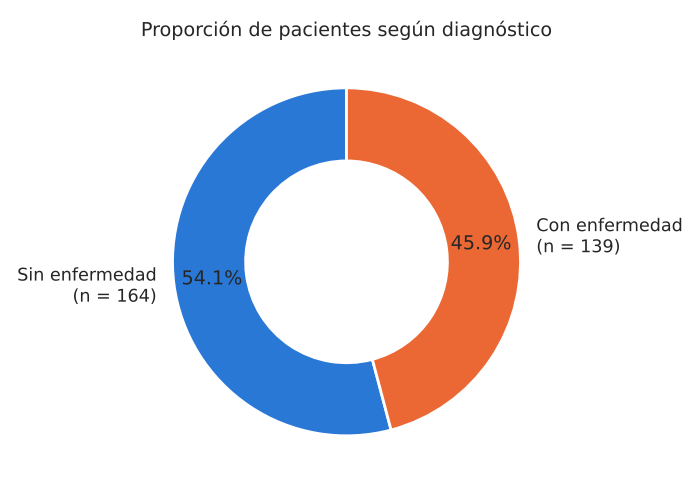

In [11]:
conteo = df_limpio["diagnostico"].value_counts()[orden]
fig, ax = plt.subplots(figsize=(7,5))
ax.pie(conteo, labels=[f"{i}\n(n = {v})" for i,v in conteo.items()], colors=list(colores.values()),
       autopct="%1.1f%%", pctdistance=0.78, startangle=90,
       wedgeprops={"width":0.42, "edgecolor":"white", "linewidth":2})
ax.set_title("Proporción de pacientes según diagnóstico")
plt.tight_layout(); plt.savefig("g1_dona.png", dpi=200); plt.show()

### 6.2 Histograma – edad

enfermedad   0   1  % enfermos
age                           
(25, 45]    47  16        25.4
(45, 55]    55  33        37.5
(55, 65]    45  74        62.2
(65, 80]    17  16        48.5


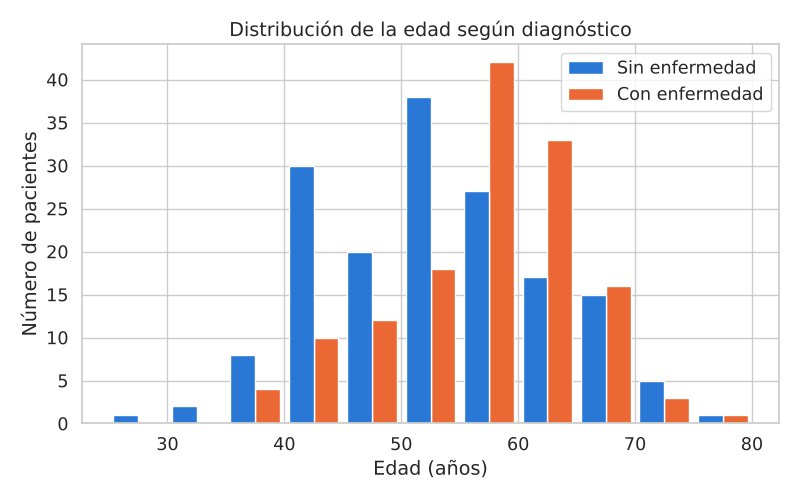

In [12]:
fig, ax = plt.subplots(figsize=(8,5))
sns.histplot(data=df_limpio, x="age", hue="diagnostico", hue_order=orden, palette=colores,
             bins=range(25,85,5), multiple="dodge", shrink=0.85, alpha=1, ax=ax)
ax.set(title="Distribución de la edad según diagnóstico", xlabel="Edad (años)", ylabel="Número de pacientes")
ax.get_legend().set_title("")
plt.tight_layout(); plt.savefig("g2_histograma.png", dpi=200); plt.show()
t = pd.crosstab(pd.cut(df_limpio["age"], [25,45,55,65,80]), df_limpio["enfermedad"])
t["% enfermos"] = (t[1]/(t[0]+t[1])*100).round(1)
print(t)

### 6.3 Barras – tipo de dolor torácico

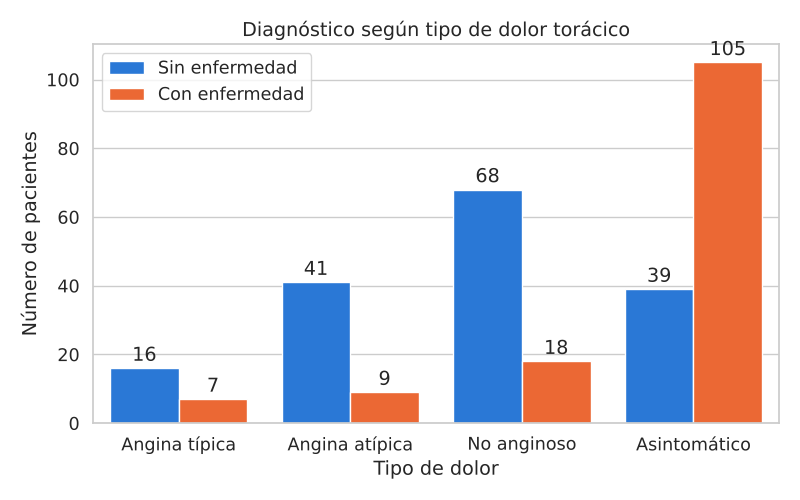

In [13]:
orden_dolor = ["Angina típica","Angina atípica","No anginoso","Asintomático"]
fig, ax = plt.subplots(figsize=(8,5))
sns.countplot(data=df_limpio, x="dolor", hue="diagnostico", order=orden_dolor,
              hue_order=orden, palette=colores, saturation=1, ax=ax)
for barras in ax.containers: ax.bar_label(barras, padding=2)
ax.set(title="Diagnóstico según tipo de dolor torácico", xlabel="Tipo de dolor", ylabel="Número de pacientes")
ax.legend(title="")
plt.tight_layout(); plt.savefig("g3_barras.png", dpi=200); plt.show()

### 6.4 Boxplot – depresión del segmento ST (`oldpeak`)

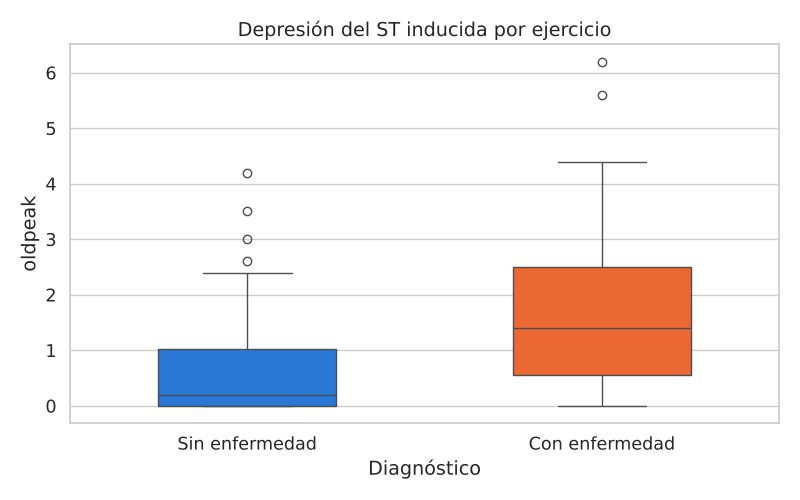

In [14]:
fig, ax = plt.subplots(figsize=(8,5))
sns.boxplot(data=df_limpio, x="diagnostico", y="oldpeak", order=orden, hue="diagnostico",
            palette=colores, saturation=1, width=0.5, legend=False, ax=ax)
ax.set(title="Depresión del ST inducida por ejercicio", xlabel="Diagnóstico", ylabel="oldpeak")
plt.tight_layout(); plt.savefig("g4_boxplot.png", dpi=200); plt.show()

### 6.5 Dispersión – edad vs. frecuencia cardíaca máxima

r edad-thalach: -0.394


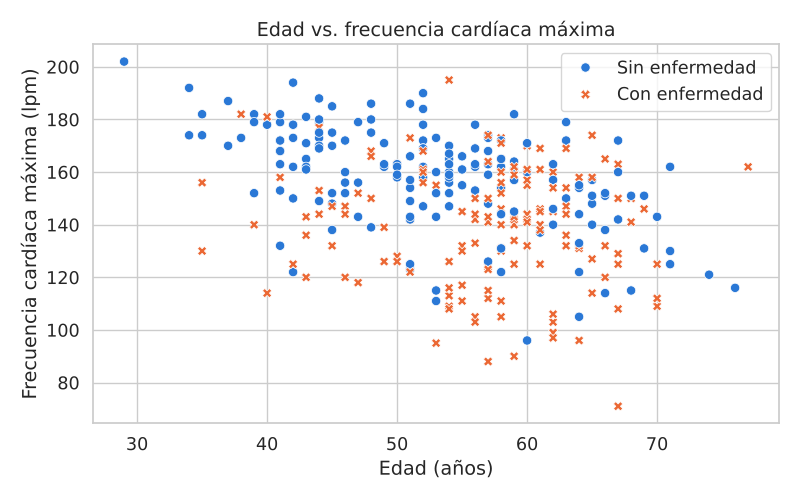

In [15]:
fig, ax = plt.subplots(figsize=(8,5))
sns.scatterplot(data=df_limpio, x="age", y="thalach", hue="diagnostico", hue_order=orden,
                style="diagnostico", style_order=orden, markers=["o","X"], palette=colores, s=45, ax=ax)
ax.set(title="Edad vs. frecuencia cardíaca máxima", xlabel="Edad (años)", ylabel="Frecuencia cardíaca máxima (lpm)")
ax.legend(title="")
plt.tight_layout(); plt.savefig("g5_dispersion.png", dpi=200); plt.show()
print("r edad-thalach:", round(df_limpio["age"].corr(df_limpio["thalach"]),3))

### 6.6 Mapa de calor – correlaciones
Solo variables numéricas, binarias y `ca`. Se excluyen `cp`, `restecg`, `slope` y `thal` porque sus códigos son categorías y la correlación de Pearson no sería interpretable.

enfermedad    1.000
ca            0.460
exang         0.432
oldpeak       0.425
sex           0.277
age           0.223
trestbps      0.151
chol          0.085
fbs           0.025
thalach      -0.417
Name: enfermedad, dtype: float64


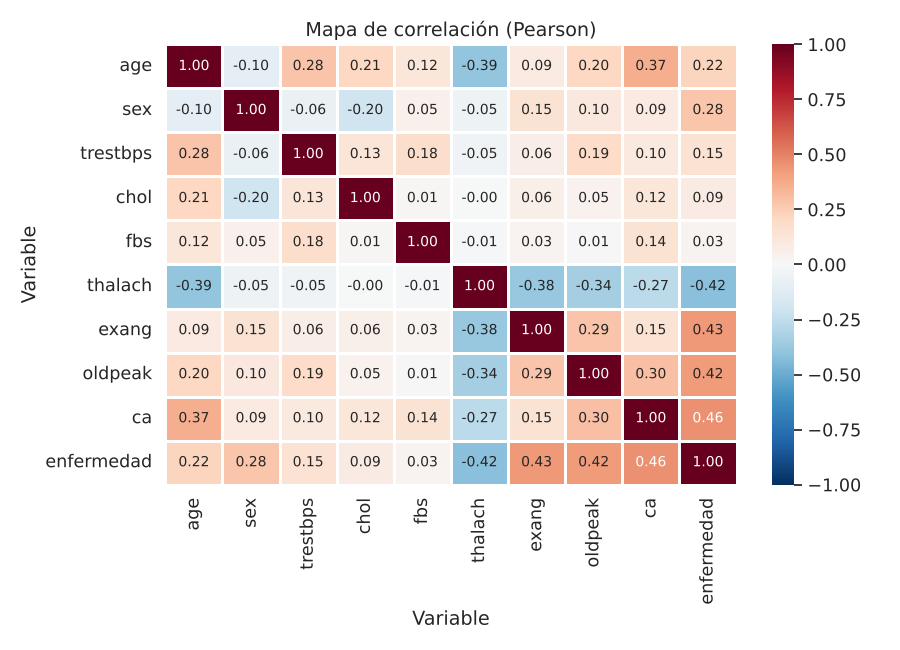

In [16]:
vars_corr = ["age","sex","trestbps","chol","fbs","thalach","exang","oldpeak","ca","enfermedad"]
corr = df_limpio[vars_corr].corr()
fig, ax = plt.subplots(figsize=(9,6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            linewidths=1, annot_kws={"size":10}, ax=ax)
ax.set(title="Mapa de correlación (Pearson)", xlabel="Variable", ylabel="Variable")
plt.tight_layout(); plt.savefig("g6_heatmap.png", dpi=200); plt.show()
print(corr["enfermedad"].sort_values(ascending=False).round(3))

## 7. Conclusiones
1. La enfermedad se asocia principalmente con el dolor torácico **asintomático**, la **angina inducida por ejercicio**, más **vasos coloreados** (`ca`), mayor **`oldpeak`**, menor **frecuencia cardíaca máxima** y **talio con defecto reversible** (76.1 % vs. 22.6 % con resultado normal).
2. La proporción de enfermos aumenta con la edad hasta el grupo de 56–65 años.
3. En esta muestra los hombres presentan una proporción de enfermedad mayor que las mujeres.
4. El colesterol y la glucosa en ayunas muestran una relación muy débil con el diagnóstico.

**Alcance:** son asociaciones, no prueban causalidad.
**Limitaciones:** 303 pacientes, un solo centro, datos de los años 80, pacientes ya remitidos por sospecha, pocas mujeres y 6 valores imputados.
**Siguientes pasos:** pruebas estadísticas, validar con las otras tres bases y entrenar un modelo de clasificación.